# Avalanche buildup time and current slope vs overvoltage
For every device configuration (folder prefix) and bias, the seeds are filtered with a
Savitzky-Golay filter and flagged as *avalanche* when the filtered current crosses `I_threshold`
and stays above it until the end of the run. The breakdown voltage $V_{BD}$ of each DI comes from a fit of the avalanche probability
vs bias; for the biases above $V_{BD}$ (overvoltage $V_{OV} = |V| - |V_{BD}|$) it computes

- the **avalanche buildup time (ABT)**: first time the filtered current reaches `I_threshold`;
- the **relative current slope (RCS)**, i.e. the avalanche growth rate $d\ln I/dt = 1/\tau$: slope of $\ln$ of the
  filtered current, fitted where it rises through `[I_fit_min, I_fit_max]`.

Figures are saved in `SAVE_DIR` as `.png`, `.pdf` and editable `.mplfig`
(reopen with `python open_fig.py <file>.mplfig` or `mcplot.load_figure`).

In [9]:
# Interactive figures (zoom/pan) need ipympl; otherwise fall back to static figures
try:
    import ipympl  # noqa: F401
    get_ipython().run_line_magic("matplotlib", "widget")
except ImportError:
    get_ipython().run_line_magic("matplotlib", "inline")
import hashlib
import os
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import re

import matplotlib.lines as mlines
import pandas as pd
from scipy.signal import savgol_filter

from mcplot import extract_vdc_from_folder, find_seed_folders, read_current_voltage, seed_number
from mcplot import save_figure, set_style

set_style(24)

SAVE_FIGURES = True  # save every figure as .png, .pdf and editable .mplfig
SAVE_DIR = "output/new_II"


def save(fig, name, editable=True):
    """Save fig as SAVE_DIR/name.{png,pdf} and, if editable, .mplfig (reopen it with open_fig.py)."""
    if SAVE_FIGURES:
        save_figure(fig, os.path.join(SAVE_DIR, name), formats=("png", "pdf"), dpi=300, bbox_inches="tight",
                    editable=editable)

# Simulation folders
Searched as `<base_path>/<prefix>-<V>V-s<seed>`; the label is the number in the prefix, e.g. `deep_implant_1.0` → `1.0 µm`.

In [10]:
base_path = "/home/angelo/server/csmhome2/amudano/Projects/MC3D/DEMC/SPAD_FBK_v2/quasi_1D"
voltages = np.linspace(-30, -45, 16)
subfolder_prefixes = [
    "FF/deep_implant_1.0/breakdown",
    "FF/deep_implant_1.1/breakdown",
    "FF/deep_implant_1.2/breakdown",
    "FF/deep_implant_1.3/breakdown",
    # "FF/deep_implant_1.4/breakdown",
    # "FF/deep_implant_1.5/breakdown",
    # "FF/deep_implant_1.6/breakdown",
    # "FF/deep_implant_1.7/breakdown",
]
contact = "ncontact"


def thickness_label(prefix):
    """"FF/deep_implant_1.0/breakdown" -> "1.0 µm"."""
    raw = prefix.split("/")[-2] if "/" in prefix else prefix
    match = re.search(r"_(\d+\.?\d*)", raw)
    return f"{match.group(1)} µm" if match else raw


def file_tag(label):
    """Label usable in file names (no spaces or µ): "1.0 µm" -> "1.0um"."""
    return label.replace(" µm", "um").replace(" ", "_")


folders_by_prefix = find_seed_folders(base_path, subfolder_prefixes, voltages, label_fn=thickness_label)


1.0 µm: Found 480 folders
  FF/deep_implant_1.0/breakdown--30.00V-s2
  FF/deep_implant_1.0/breakdown--31.00V-s2
  FF/deep_implant_1.0/breakdown--32.00V-s2
  FF/deep_implant_1.0/breakdown--33.00V-s2
  FF/deep_implant_1.0/breakdown--34.00V-s2
  ... and 475 more

1.1 µm: Found 480 folders
  FF/deep_implant_1.1/breakdown--30.00V-s2
  FF/deep_implant_1.1/breakdown--31.00V-s2
  FF/deep_implant_1.1/breakdown--32.00V-s2
  FF/deep_implant_1.1/breakdown--33.00V-s2
  FF/deep_implant_1.1/breakdown--34.00V-s2
  ... and 475 more

1.2 µm: Found 480 folders
  FF/deep_implant_1.2/breakdown--30.00V-s2
  FF/deep_implant_1.2/breakdown--31.00V-s2
  FF/deep_implant_1.2/breakdown--32.00V-s2
  FF/deep_implant_1.2/breakdown--33.00V-s2
  FF/deep_implant_1.2/breakdown--34.00V-s2
  ... and 475 more

1.3 µm: Found 480 folders
  FF/deep_implant_1.3/breakdown--30.00V-s2
  FF/deep_implant_1.3/breakdown--31.00V-s2
  FF/deep_implant_1.3/breakdown--32.00V-s2
  FF/deep_implant_1.3/breakdown--33.00V-s2
  FF/deep_implant_

# Data post processing

In [11]:
I_threshold = 1e-6  # A; avalanche: the filtered current crosses I_threshold and stays above it until the
#                       end of the run; ABT: first time the filtered current reaches I_threshold
I_fit_min, I_fit_max = 2e-6, 15e-6  # A: window of the filtered current for the d(ln I)/dt fit

# Savitzky-Golay filter
sv_time_window_ps = 0.5  # target window length (ps); the sampling step is taken from each file
polyorder = 3

n_workers = 8  # files read in parallel; lower it if the sshfs mount refuses many reads

# Local cache of the filtered current and time of every run (float32 .npz). A run is read again from the
# server when its file changes (size or modification time) or when the filter parameters or the contact
# change (they are part of the cache file name). Delete CACHE_DIR to free the space of old parameters.
USE_CACHE = True
CACHE_DIR = "cache/seed_runs"


def sv_window(n_points, time_step_fs):
    """Odd window of ~sv_time_window_ps for the sampling step time_step_fs, reduced to
    n_points // 5 (odd, > polyorder + 1) for short transients."""
    target_window_pts = max(int(sv_time_window_ps * 1000 / time_step_fs) | 1, polyorder + 2)
    if target_window_pts <= n_points // 5:
        return target_window_pts
    window = max(n_points // 5, polyorder + 2)
    return window + 1 if window % 2 == 0 else window


def retry(func, *args, n_tries=5, wait_s=2.0):
    """func(*args), retried: the sshfs mount refuses some operations when many files are opened."""
    for attempt in range(n_tries):
        try:
            return func(*args)
        except Exception:
            if attempt == n_tries - 1:
                raise
            time.sleep(wait_s)


def read_with_retry(current_file):
    return retry(read_current_voltage, current_file, contact)


def read_raw_current(s):
    """Raw |current| of a seed, re-read from its file (only the filtered current is kept in memory)."""
    current, _, _, _ = read_with_retry(s["file"])
    return np.abs(current.to_numpy())


def cache_path(current_file):
    """Cache file of a run for the current contact and filter parameters."""
    key = f"{current_file}|{contact}|{sv_time_window_ps}|{polyorder}"
    return os.path.join(CACHE_DIR, hashlib.md5(key.encode()).hexdigest() + ".npz")


def read_filtered(current_file):
    """(filtered |current|, time) of a run in float32, from the cache if it is up to date.

    Returns also True if the cache was used."""
    stat = retry(os.stat, current_file)
    cache_file = cache_path(current_file)
    if USE_CACHE and os.path.exists(cache_file):
        with np.load(cache_file) as cached:
            if cached["size"] == stat.st_size and cached["mtime"] == stat.st_mtime:
                return cached["current_filt"], cached["time"], True
    current, _, time_s, _ = read_with_retry(current_file)
    curr = np.abs(current.to_numpy())
    t = time_s.to_numpy()
    time_step_fs = np.median(np.diff(t)) * 1e15  # time column is in s
    curr_filt = savgol_filter(curr, sv_window(len(curr), time_step_fs), polyorder).astype(np.float32)
    t = t.astype(np.float32)
    if USE_CACHE:
        os.makedirs(CACHE_DIR, exist_ok=True)
        tmp_file = cache_file.removesuffix(".npz") + ".tmp.npz"  # written fully, then renamed
        np.savez(tmp_file, current_filt=curr_filt, time=t, size=stat.st_size, mtime=stat.st_mtime)
        os.replace(tmp_file, cache_file)
    return curr_filt, t, False


def try_load_seed(current_file):
    """(seed, from_cache, None), or (None, False, exception) if the file cannot be read.

    Avalanche flag: the filtered current crosses I_threshold and stays above it until the end."""
    try:
        curr_filt, t, from_cache = read_filtered(current_file)
    except Exception as e:
        return None, False, e
    below = np.flatnonzero(curr_filt < I_threshold)  # crossing: below at some point, above at the end
    seed = {
        "flag": bool(len(below) > 0 and below[-1] < len(curr_filt) - 1),
        "current_filt": curr_filt,
        "time": t,
        "file": current_file,
    }
    return seed, from_cache, None


# data_dict[prefix][vdc][seed] = {"flag", "current_filt", "time", "file"}; arrays in float32 to save memory
jobs = [(prefix, folder) for prefix, folders in folders_by_prefix.items() for folder in folders]
data_dict = {prefix: {} for prefix in folders_by_prefix}
n_failed = n_cached = 0
t_start = time.time()
with ThreadPoolExecutor(n_workers) as pool:
    loaded = pool.map(try_load_seed, [f"{base_path}/{folder}/contact_current.csv" for _, folder in jobs])
    for (prefix, folder), (seed, from_cache, error) in zip(jobs, loaded):  # in the order of jobs
        seeds = data_dict[prefix].setdefault(extract_vdc_from_folder(folder), {})
        if error is not None:
            print(f"  Error reading {base_path}/{folder}/contact_current.csv: {error!r}")
            n_failed += 1
            continue
        seeds[seed_number(folder)] = seed
        n_cached += from_cache
print(f"Read {len(jobs) - n_failed} runs ({n_cached} from the cache) in {time.time() - t_start:.0f} s "
      f"with {n_workers} threads")
for prefix, vdc_dict in data_dict.items():
    print(f"  {prefix}: {sum(len(seeds) for seeds in vdc_dict.values())} runs")
if n_failed:
    print(f"\nWARNING: {n_failed} files could not be read; the seed counts (and V_BD) may be affected")

Read 1920 runs (0 from the cache) in 239 s with 8 threads
  1.0 µm: 480 runs
  1.1 µm: 480 runs
  1.2 µm: 480 runs
  1.3 µm: 480 runs


## Filter calibration
Raw and filtered current of a few avalanche seeds at the highest |V| (fastest avalanche) of the first prefix.

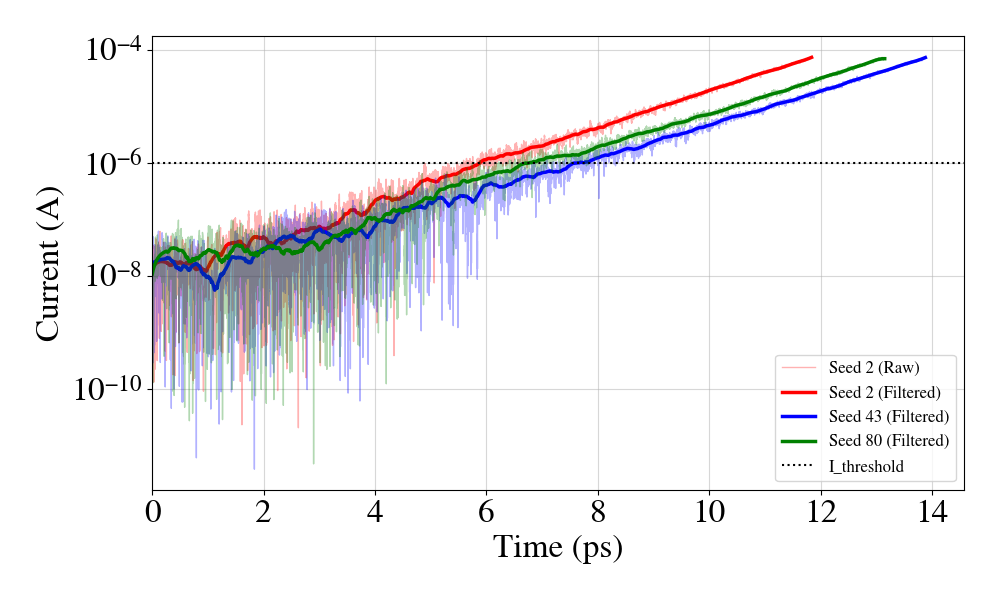

In [12]:
plt.close("all")
n_test_seeds = 3
test_prefix = next(iter(data_dict))
valid_vdcs = [v for v, seeds in data_dict[test_prefix].items() if any(s["flag"] for s in seeds.values())]
test_vdc = max(valid_vdcs, key=abs)
test_seeds = [(seed, s) for seed, s in data_dict[test_prefix][test_vdc].items() if s["flag"]][:n_test_seeds]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["r", "b", "g", "m", "c"]
for i, (seed, s) in enumerate(test_seeds):
    c = colors[i % len(colors)]
    t_ps = s["time"] * 1e12
    ax.semilogy(t_ps, read_raw_current(s), color=c, alpha=0.3, linewidth=1,
                label=f"Seed {seed} (Raw)" if i == 0 else "_nolegend_")
    ax.semilogy(t_ps, s["current_filt"], color=c, linewidth=2.5, label=f"Seed {seed} (Filtered)")
ax.axhline(I_threshold, color="k", linestyle=":", label="I_threshold")
ax.set_xlabel("Time (ps)")
ax.set_ylabel("Current (A)")
ax.set_xlim(left=0)
ax.grid(True, which="both", alpha=0.5)
ax.legend(fontsize=12)
fig.tight_layout()
save(fig, "test_filter")
plt.show()

## Breakdown voltage, buildup time and slope
For each DI the avalanche probability is fitted, by binomial maximum likelihood on the $k$ avalanching
runs out of the $n$ seeds read at every bias, with
$$P(V) = 1 - \exp\left(-\frac{|V| - V_{BD}}{a}\right) \text{ for } |V| > V_{BD}, \qquad P = 0 \text{ otherwise}.$$
$V_{BD}$ is the physical breakdown voltage, $a$ sets how fast $P$ rises; its uncertainty comes from a
parametric bootstrap. ABT and RCS are computed for the biases with $|V| > |V_{BD}|$ and at least
`n_min_avalanche` avalanching runs, with error bars std/$\sqrt{n}$.
Seeds without enough points in the RCS fit window give `nan`, as do biases with no slope at all.

In [13]:
from scipy.optimize import minimize

n_min_avalanche = 5  # minimum avalanching runs for a point in the ABT and RCS plots
n_bootstrap = 200  # parametric bootstrap resamples for the uncertainty of V0
rcs_min_span = 3.0  # RCS fitted only if the current spans at least this factor (max/min) in the fit window
rng = np.random.default_rng(0)


def relative_slope(t, current):
    """d(ln I)/dt (1/s): line fit of ln(I) on the last rise of the current through [I_fit_min, I_fit_max]
    before it first exceeds I_fit_max (up to the peak if it never does); nan with fewer than 2 points or
    if the current spans less than a factor rcs_min_span in that stretch."""
    above = np.flatnonzero(current > I_fit_max)
    stop = above[0] if len(above) else np.argmax(current) + 1
    below = np.flatnonzero(current[:stop] < I_fit_min)
    start = below[-1] + 1 if len(below) else 0
    if stop - start < 2 or current[start:stop].max() < rcs_min_span * current[start:stop].min():
        return np.nan
    t_fit, i_fit = t[start:stop].astype(float), current[start:stop].astype(float)  # float64 for the fit
    return np.polyfit(t_fit, np.log(i_fit), 1)[0]


def mean_std_sem(values):
    """Mean, sample std (n - 1) and standard error of the mean std/sqrt(n), ignoring nan.

    All nan if no finite value; std and sem nan with a single value."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return np.nan, np.nan, np.nan
    std = values.std(ddof=1) if len(values) > 1 else np.nan
    return values.mean(), std, std / np.sqrt(len(values))


def avalanche_probability(v_abs, v0, a):
    """P(|V|) = 1 - exp(-(|V| - V0) / a) for |V| > V0, 0 otherwise (|V| and V0 positive)."""
    return np.where(v_abs > v0, -np.expm1(-(v_abs - v0) / a), 0.0)


def fit_breakdown(v_abs, k, n):
    """Binomial maximum likelihood fit of avalanche_probability to k avalanching runs out of n.

    The likelihood is not smooth in V0, so Nelder-Mead is started from a grid of (V0, a) and the
    best fit is kept. Returns (V0, a), V0 positive.
    """
    def nll(params):
        v0, log_a = params
        p = np.clip(avalanche_probability(v_abs, v0, np.exp(log_a)), 1e-9, 1 - 1e-9)
        return -np.sum(k * np.log(p) + (n - k) * np.log(1 - p))

    v_min = v_abs[k > 0].min()  # lowest |V| with an avalanche
    best = None
    for v0_start in np.arange(v_min - 1, v_min + 1.5 + 1e-9, 0.25):
        for a_start in (0.5, 1, 2):
            fit = minimize(nll, [v0_start, np.log(a_start)], method="Nelder-Mead")
            if best is None or fit.fun < best.fun:
                best = fit
    return best.x[0], np.exp(best.x[1])


results_by_prefix = {}
for prefix, vdc_dict in data_dict.items():
    vdcs = sorted((v for v, seeds in vdc_dict.items() if seeds), key=abs)
    v_abs = np.abs(vdcs)
    n = np.array([len(vdc_dict[v]) for v in vdcs])
    k = np.array([sum(s["flag"] for s in vdc_dict[v].values()) for v in vdcs])
    if not k.any():
        print(f"{prefix}: no avalanching runs, VBD cannot be fitted: skipped")
        continue

    v0_abs, a = fit_breakdown(v_abs, k, n)
    p_fit = avalanche_probability(v_abs, v0_abs, a)
    v0_boot = [fit_breakdown(v_abs, k_boot, n)[0]
               for k_boot in rng.binomial(n, p_fit, size=(n_bootstrap, len(n))) if k_boot.any()]
    sigma_v0 = np.std(v0_boot)
    sign = -1.0 if vdcs[0] < 0 else 1.0  # V0 with the sign of the biases
    v0 = sign * v0_abs
    print(f"{prefix}: VBD = {v0:.2f} ± {sigma_v0:.2f} V, a = {a:.2f} V, "
          f"V50 = {sign * (v0_abs + a * np.log(2)):.2f} V")

    res = {f"{stat}_{key}": [] for key in ("time", "slope", "product") for stat in ("avg", "std", "sem", "n")}
    res["vov"] = []
    avg_t_by_vdc = {}
    for vdc in sorted(vdc_dict, key=abs):
        avg_t_by_vdc[vdc] = None
        flagged = [s for s in vdc_dict[vdc].values() if s["flag"]]
        if abs(vdc) <= v0_abs or len(flagged) < n_min_avalanche:
            continue
        times, slopes = [], []  # ABT (ps) and RCS (1/s) of every avalanching seed, nan if missing
        for s in flagged:
            above = np.where(s["current_filt"] >= I_threshold)[0]
            times.append(s["time"][above[0]] * 1e12 if len(above) > 0 else np.nan)
            slopes.append(relative_slope(s["time"], s["current_filt"]))
        times, slopes = np.array(times), np.array(slopes)
        products = times * slopes * 1e-12  # ABT x RCS of each seed (dimensionless)
        if not np.isfinite(times).any():
            continue

        avg_t_by_vdc[vdc] = np.nanmean(times)
        n_nan = int(np.isnan(slopes).sum())
        print(f"  {vdc:g} V: V_OV = {abs(vdc) - v0_abs:.2f} V, {len(flagged)}/{len(vdc_dict[vdc])} avalanching runs"
              + (f", {n_nan} without slope (nan)" if n_nan else ""))
        res["vov"].append(abs(vdc) - v0_abs)
        for key, values in (("time", times), ("slope", slopes), ("product", products)):
            avg, std, sem = mean_std_sem(values)
            res[f"avg_{key}"].append(avg)
            res[f"std_{key}"].append(std)
            res[f"sem_{key}"].append(sem)
            res[f"n_{key}"].append(int(np.isfinite(values).sum()))

    results_by_prefix[prefix] = {key: np.array(v) for key, v in res.items()}
    results_by_prefix[prefix].update(avg_t_by_vdc=avg_t_by_vdc, v0=v0, sigma_v0=sigma_v0, a=a,
                                     fit_data=(v_abs, k, n))

print("\nAvalanche buildup time computed.")

1.0 µm: VBD = -32.66 ± 0.17 V, a = 1.78 V, V50 = -33.89 V
  -33 V: V_OV = 0.34 V, 5/30 avalanching runs, 5 without slope (nan)
  -34 V: V_OV = 1.34 V, 16/30 avalanching runs, 3 without slope (nan)
  -35 V: V_OV = 2.34 V, 24/30 avalanching runs
  -36 V: V_OV = 3.34 V, 24/30 avalanching runs
  -37 V: V_OV = 4.34 V, 27/30 avalanching runs
  -38 V: V_OV = 5.34 V, 29/30 avalanching runs
  -39 V: V_OV = 6.34 V, 30/30 avalanching runs
  -40 V: V_OV = 7.34 V, 29/30 avalanching runs
  -41 V: V_OV = 8.34 V, 30/30 avalanching runs
  -42 V: V_OV = 9.34 V, 29/30 avalanching runs
  -43 V: V_OV = 10.34 V, 30/30 avalanching runs
  -44 V: V_OV = 11.34 V, 30/30 avalanching runs
  -45 V: V_OV = 12.34 V, 30/30 avalanching runs
1.1 µm: VBD = -35.43 ± 0.20 V, a = 1.54 V, V50 = -36.50 V
  -36 V: V_OV = 0.57 V, 9/30 avalanching runs, 8 without slope (nan)
  -37 V: V_OV = 1.57 V, 20/30 avalanching runs, 1 without slope (nan)
  -38 V: V_OV = 2.57 V, 24/30 avalanching runs
  -39 V: V_OV = 3.57 V, 26/30 avalanchi

## Breakdown fit
Avalanche fraction $k/n$ vs $|V|$ with binomial error bars $\sqrt{p(1-p)/n}$, the fitted $P(V)$ and $|V_{BD}|$.

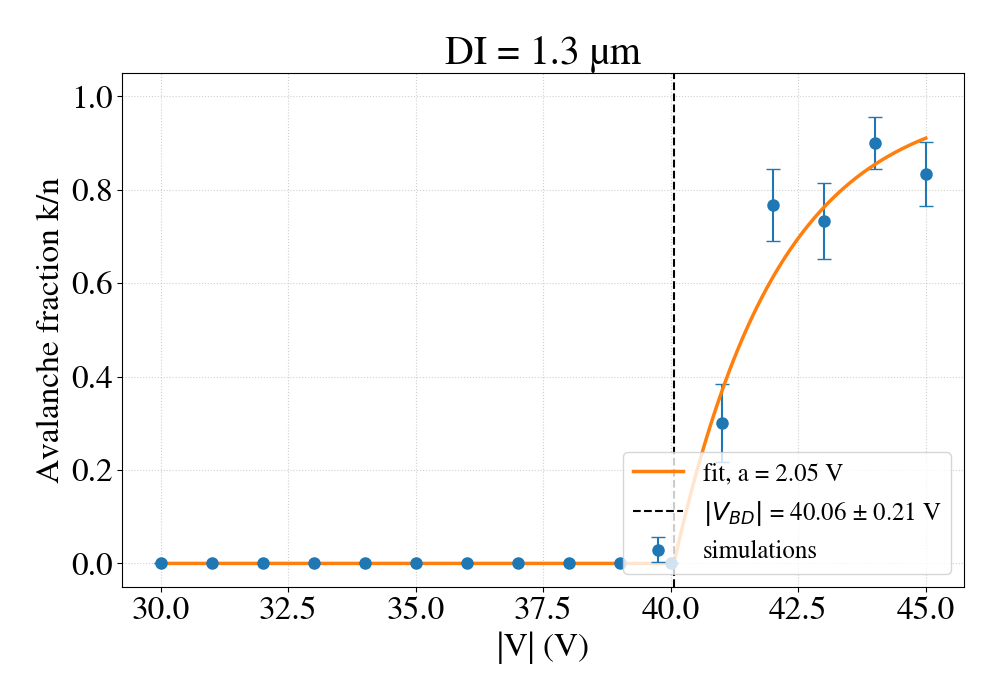

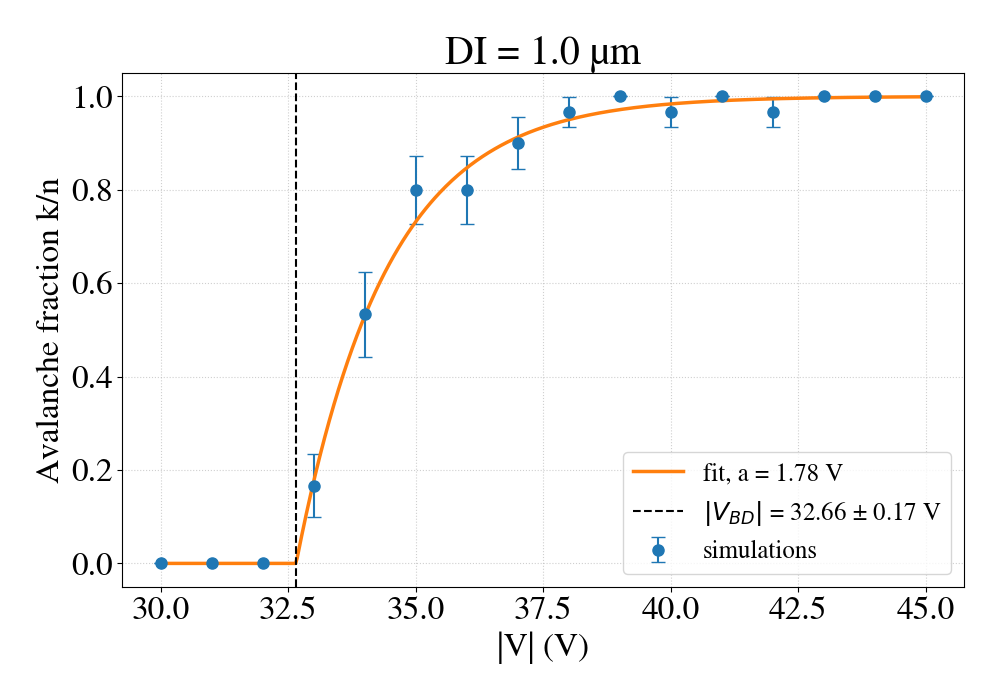

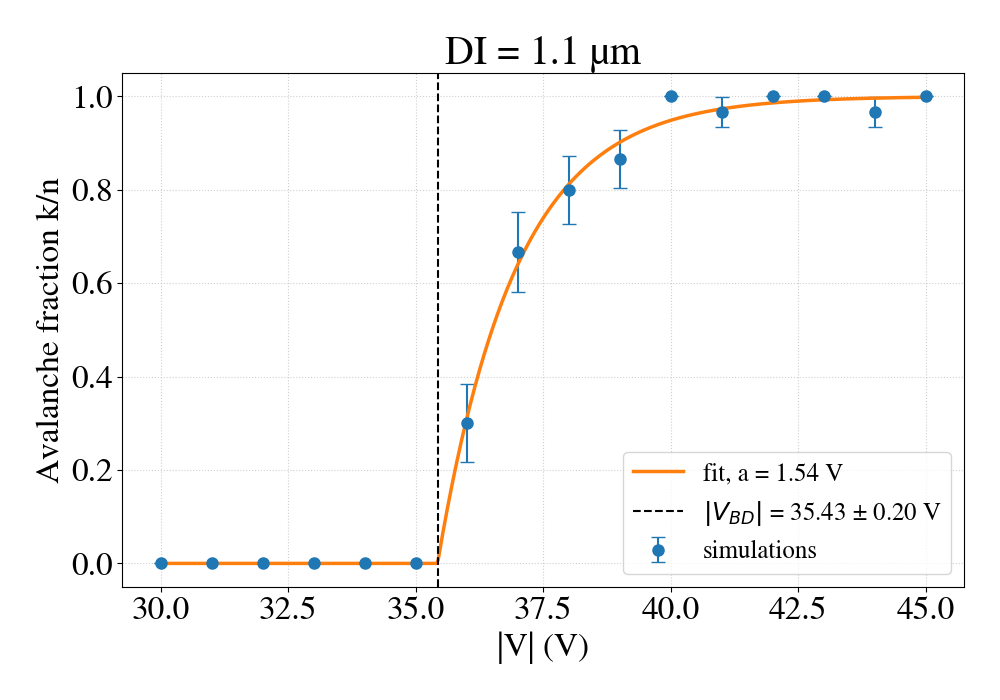

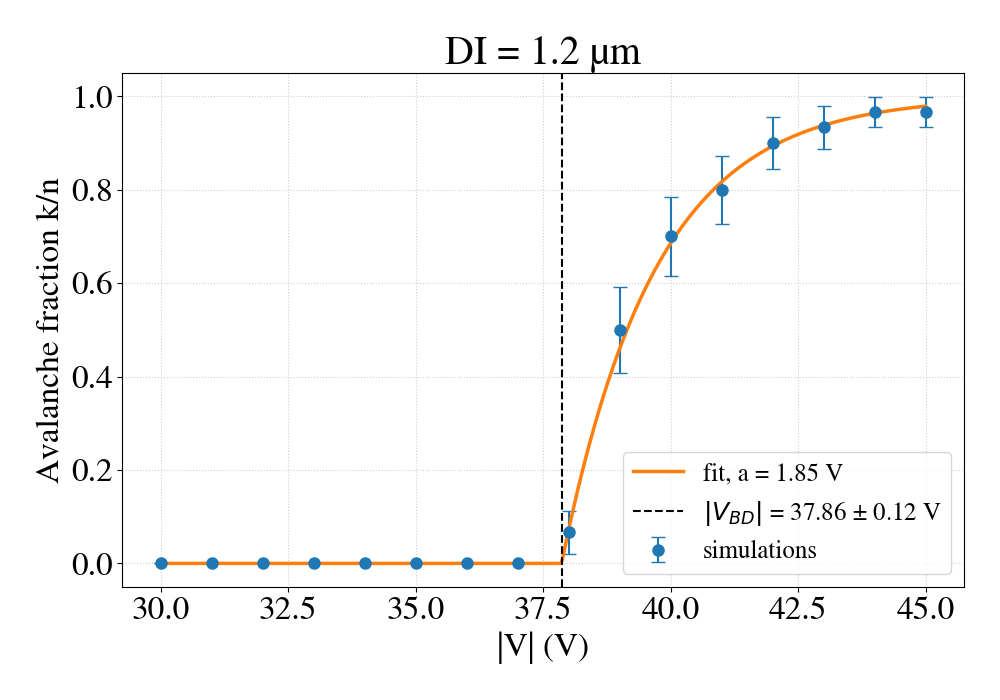

In [14]:
plt.close("all")
for prefix, data in results_by_prefix.items():
    v_abs, k, n = data["fit_data"]
    frac = k / n
    v_line = np.linspace(v_abs.min(), v_abs.max(), 500)
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.errorbar(v_abs, frac, yerr=np.sqrt(frac * (1 - frac) / n), fmt="o", markersize=8, capsize=5,
                color="C0", label="simulations")
    ax.plot(v_line, avalanche_probability(v_line, abs(data["v0"]), data["a"]), "-", color="C1", linewidth=2.5,
            label=f"fit, a = {data['a']:.2f} V")
    ax.axvline(abs(data["v0"]), color="k", linestyle="--",
               label=f"$|V_{{BD}}|$ = {abs(data['v0']):.2f} ± {data['sigma_v0']:.2f} V")
    ax.set_xlabel("|V| (V)")
    ax.set_ylabel("Avalanche fraction k/n")
    ax.set_title(f"DI = {prefix}")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=18, loc="lower right")
    fig.tight_layout()
    save(fig, f"breakdown_fit_{file_tag(prefix)}")
plt.show()

# Debug plots
Filtered current of every seed (grey: no avalanche) with `I_threshold` and the average ABT.
The grids are only saved (`.png`, `.pdf`), not shown here.

In [15]:
max_plot_points = 2000  # points plotted per curve (every n-th sample); the analysis uses all of them


def plot_seed_currents(ax, seeds, avg_t, avg_label="avg_t"):
    for s in seeds.values():
        step = max(1, len(s["time"]) // max_plot_points)
        t_ps, current = s["time"][::step] * 1e12, s["current_filt"][::step]
        if s["flag"]:
            ax.semilogy(t_ps, current, alpha=0.6, linewidth=1.5)
        else:
            ax.semilogy(t_ps, current, color="lightgray", alpha=0.5, linewidth=1)
    ax.axhline(I_threshold, color="r", linestyle="--", label=f"I_th={I_threshold:.0e}")
    if avg_t is not None:
        ax.axvline(avg_t, color="b", linestyle="-.", label=f"{avg_label}={avg_t:.1f} ps")
    ax.set_xlabel("Time (ps)")
    ax.set_ylabel("Current (A)")
    ax.grid(True, which="both", linestyle=":", alpha=0.6)
    ax.legend(fontsize=24, loc="best")


def bias_title(prefix, vdc):
    """"V = -36 V, 25/30 aval, V_OV = 2.7 V" (V_OV only above VBD)."""
    seeds = data_dict[prefix][vdc]
    v0 = results_by_prefix[prefix]["v0"]
    title = f"V = {vdc:g} V, {sum(s['flag'] for s in seeds.values())}/{len(seeds)} aval"
    if abs(vdc) > abs(v0):
        title += f", V_OV = {abs(vdc) - abs(v0):.1f} V"
    return title

In [16]:
plt.close("all")
n_cols = 4
for prefix, vdc_dict in data_dict.items():
    if prefix not in results_by_prefix:
        continue
    vdcs = sorted(vdc_dict, key=abs)
    n_rows = int(np.ceil(len(vdcs) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 5 * n_rows), squeeze=False)
    fig.suptitle(f"DI = {prefix}, VBD = {results_by_prefix[prefix]['v0']:.1f} V", fontsize=16, fontweight="bold")
    axes = axes.flatten()
    for ax, vdc in zip(axes, vdcs):
        plot_seed_currents(ax, vdc_dict[vdc], results_by_prefix[prefix]["avg_t_by_vdc"][vdc])
        ax.set_title(bias_title(prefix, vdc))
    for ax in axes[len(vdcs):]:
        ax.set_visible(False)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    save(fig, f"debug_plot_{file_tag(prefix)}", editable=False)  # no .mplfig: too large with all curves
    plt.close(fig)  # not shown in the notebook: open the saved .png/.pdf
    if SAVE_FIGURES:
        print(f"Saved {os.path.join(SAVE_DIR, 'debug_plot_' + file_tag(prefix))}.png/.pdf")

Saved output/new_II/debug_plot_1.0um.png/.pdf
Saved output/new_II/debug_plot_1.1um.png/.pdf
Saved output/new_II/debug_plot_1.2um.png/.pdf
Saved output/new_II/debug_plot_1.3um.png/.pdf


## Single bias

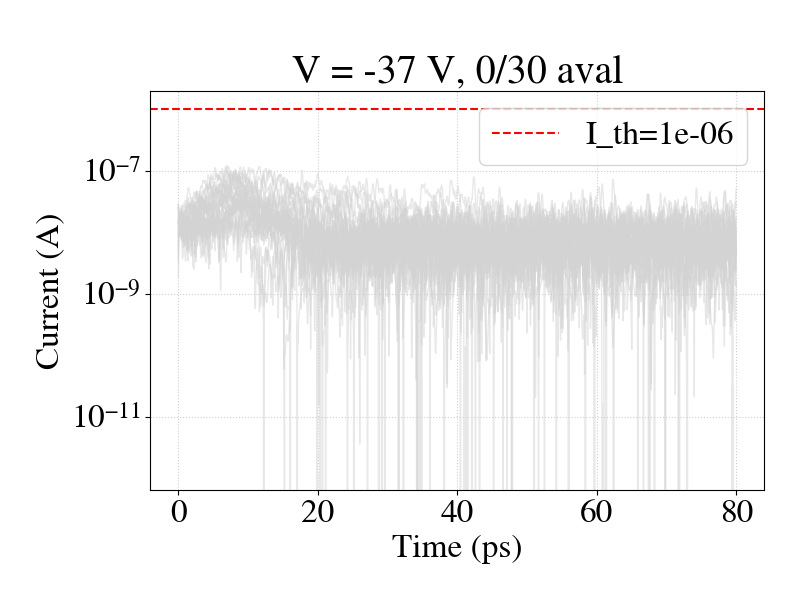

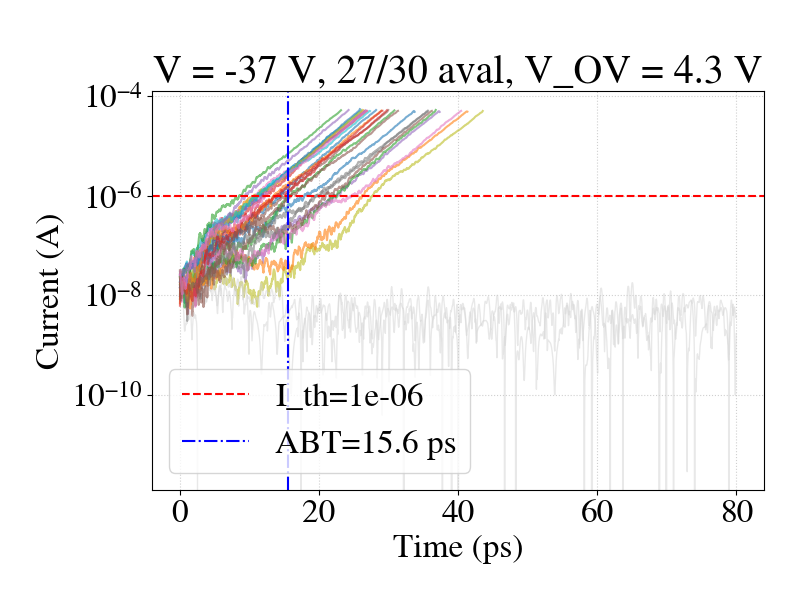

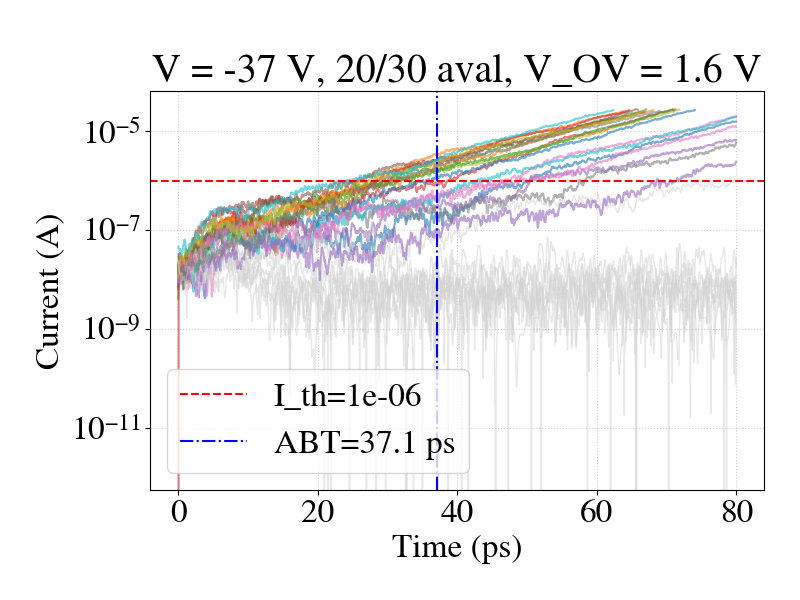

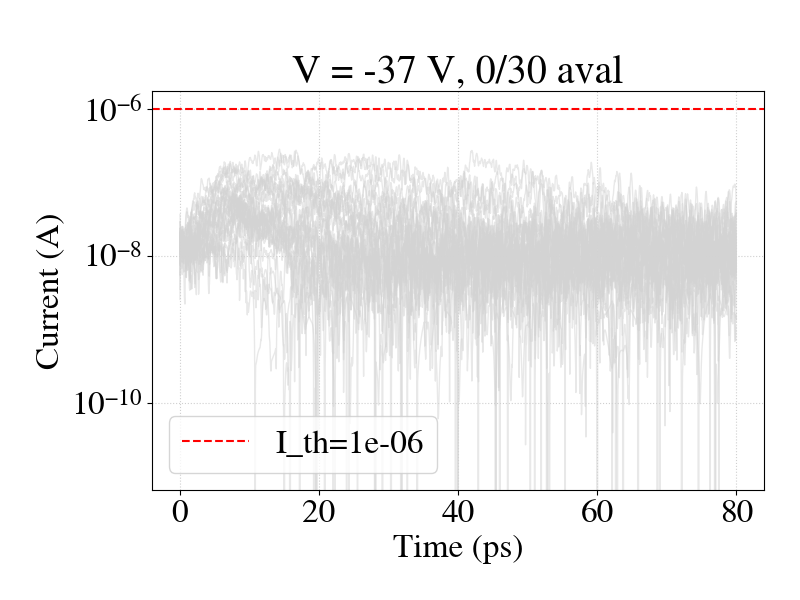

In [41]:
plt.close("all")
target_vdc = -37.0
for prefix, vdc_dict in data_dict.items():
    if prefix not in results_by_prefix:
        continue
    if target_vdc not in vdc_dict:
        print(f"{prefix}: no simulations at {target_vdc} V")
        continue
    fig, ax = plt.subplots(figsize=(8, 6))
    plot_seed_currents(ax, vdc_dict[target_vdc], results_by_prefix[prefix]["avg_t_by_vdc"][target_vdc],
                       avg_label="ABT")
    ax.set_title(bias_title(prefix, target_vdc))
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    save(fig, f"debug_plot_{file_tag(prefix)}_V{target_vdc:g}")
plt.show()

## Single curve
Raw and filtered current of one seed at one bias. With `seed = None` the first seed that develops the avalanche is used.

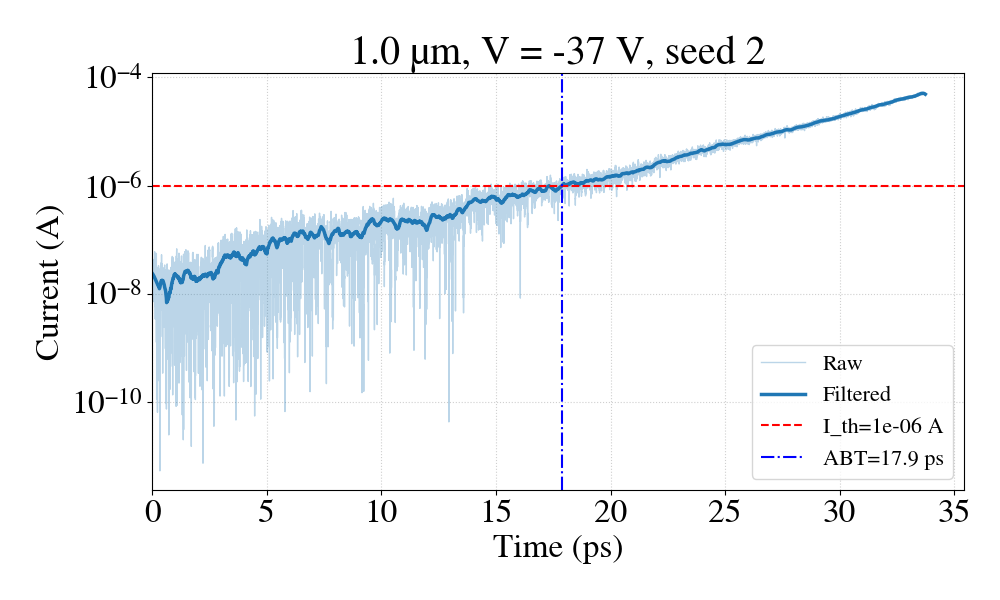

In [42]:
plt.close("all")
curve_prefix = "1.0 µm"  # one of data_dict.keys()
curve_vdc = -37.0
seed = None  # seed number, or None for the first avalanche seed

seeds = data_dict[curve_prefix][curve_vdc]
if seed is None:
    seed = next(n for n, s in seeds.items() if s["flag"])
s = seeds[seed]

# ABT of this seed: first time the filtered current reaches I_threshold (as in the analysis)
above = np.where(s["current_filt"] >= I_threshold)[0]
abt = s["time"][above[0]] * 1e12 if len(above) > 0 else None

fig, ax = plt.subplots(figsize=(10, 6))
t_ps = s["time"] * 1e12
ax.semilogy(t_ps, read_raw_current(s), color="C0", alpha=0.3, linewidth=1, label="Raw")  # re-read from the file
ax.semilogy(t_ps, s["current_filt"], color="C0", linewidth=2.5, label="Filtered")
ax.axhline(I_threshold, color="r", linestyle="--", label=f"I_th={I_threshold:.0e} A")
if abt is not None:
    ax.axvline(abt, color="b", linestyle="-.", label=f"ABT={abt:.1f} ps")
else:
    print(f"Seed {seed} never reaches I_threshold: no ABT")
ax.set_title(f"{curve_prefix}, V = {curve_vdc:g} V, seed {seed}")
ax.set_xlabel("Time (ps)")
ax.set_ylabel("Current (A)")
ax.set_xlim(left=0)
ax.grid(True, which="both", linestyle=":", alpha=0.6)
ax.legend(fontsize=16)
fig.tight_layout()
save(fig, f"current_{file_tag(curve_prefix)}_V{curve_vdc:g}_s{seed}")
plt.show()

# Results vs overvoltage
One marker/line style per prefix; ABT in blue, RCS in orange; error bars std/$\sqrt{n}$.

In [34]:
prefix_colors = plt.cm.tab10.colors
prefix_markers = ["o", "s", "^", "v", "P", "*", "X", "D", "h"]
prefix_lines = ["--", "-.", ":", "-"]
abt_hollow_ps = 40.0  # half the simulated time: points with a longer mean ABT can be drawn with hollow markers


def plot_vs_overvoltage(ax, key, scale, color=None, hollow_long_abt=False):
    """data[f"avg_{key}"] vs overvoltage, with error bars = standard error of the mean (data[f"sem_{key}"]).

    One marker per prefix. With `color`, every prefix in that color with its own line style; without, one
    color per prefix and solid lines. With hollow_long_abt, the points whose mean ABT exceeds abt_hollow_ps
    have hollow markers (still on the line).
    """
    for idx, (label, data) in enumerate(results_by_prefix.items()):
        marker = prefix_markers[idx % len(prefix_markers)]
        if color is None:
            line_color, line_style = prefix_colors[idx % len(prefix_colors)], "-"
        else:
            line_color, line_style = color, prefix_lines[idx % len(prefix_lines)]
        x, y = data["vov"], data[f"avg_{key}"] * scale
        hollow = data["avg_time"] > abt_hollow_ps if hollow_long_abt else np.zeros(len(x), dtype=bool)
        ax.errorbar(x, y, yerr=data[f"sem_{key}"] * scale, fmt=marker + line_style, markevery=list(~hollow),
                    markersize=10, linewidth=3, capsize=6, capthick=2, elinewidth=2, color=line_color, label=label)
        ax.plot(x[hollow], y[hollow], marker, mfc="none", mew=2, markersize=10, linestyle="none", color=line_color)


def prefix_legend(ax, fontsize=28):
    """Legend with one black marker/line style per prefix."""
    handles = [mlines.Line2D([], [], color="black", markersize=10, label=label,
                             marker=prefix_markers[i % len(prefix_markers)],
                             linestyle=prefix_lines[i % len(prefix_lines)])
               for i, label in enumerate(results_by_prefix)]
    ax.legend(handles=handles, ncol=max(len(handles), 1), loc="upper center", fontsize=fontsize)

## Buildup time and current slope

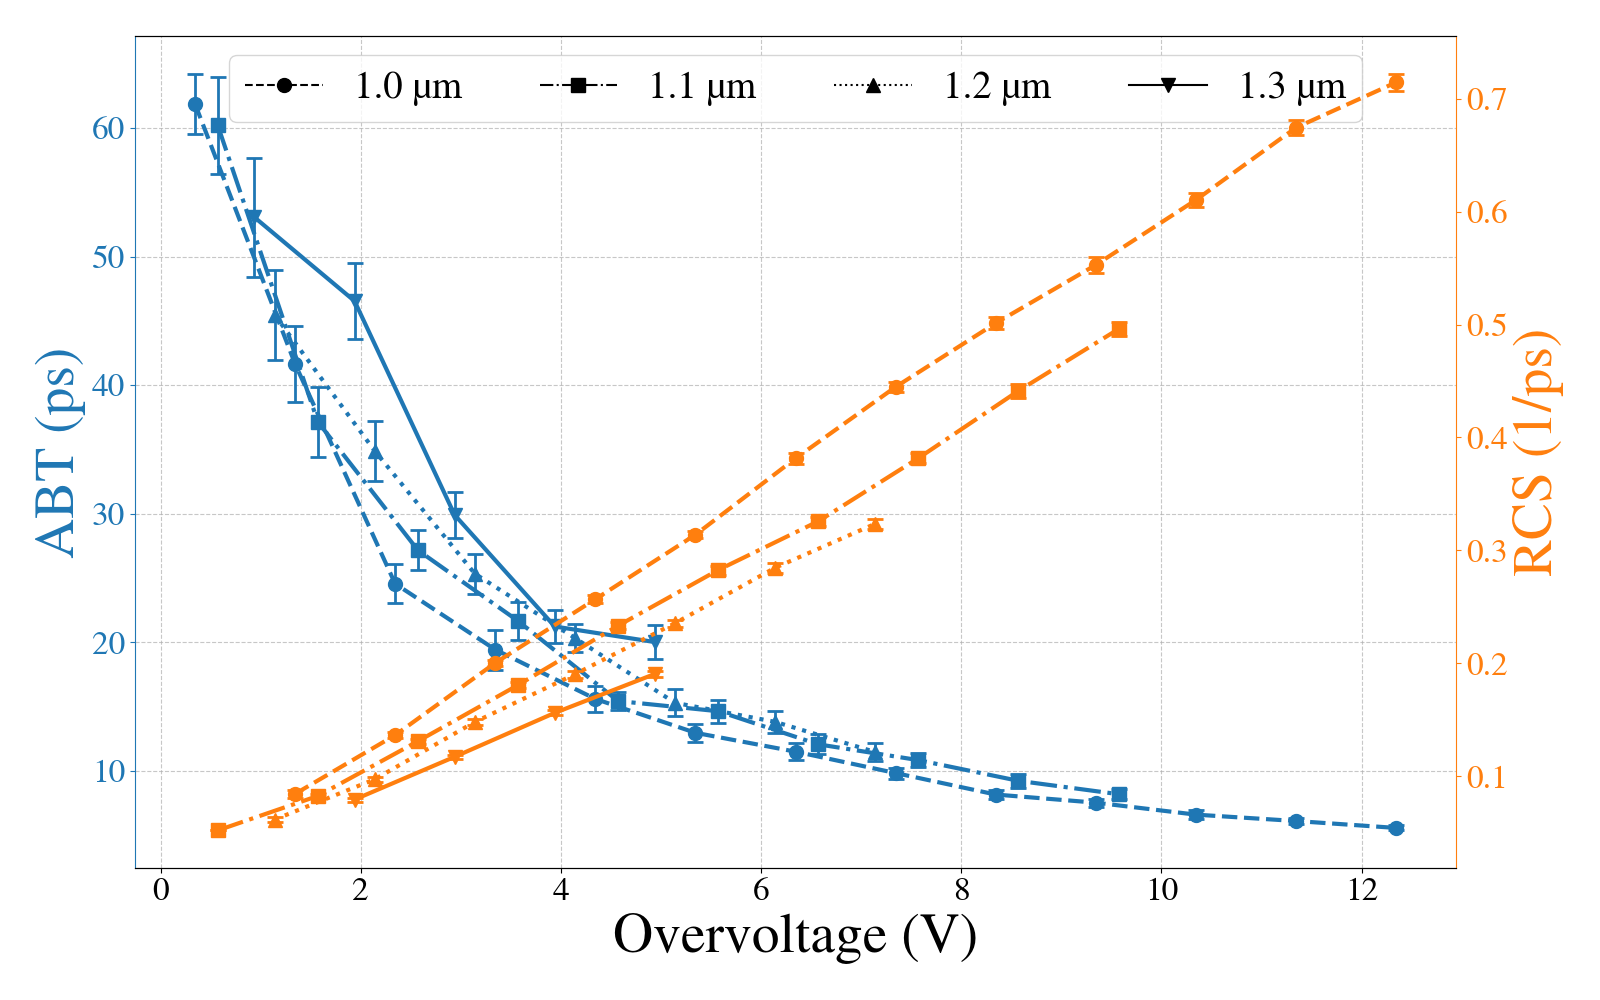

In [35]:
plt.close("all")
fig, ax1 = plt.subplots(figsize=(16, 10))
ax2 = ax1.twinx()
plot_vs_overvoltage(ax1, "time", 1, prefix_colors[0])
plot_vs_overvoltage(ax2, "slope", 1e-12, prefix_colors[1])
ax1.set_xlabel("Overvoltage (V)", fontsize=40)
ax1.grid(True, linestyle="--", alpha=0.7)
prefix_legend(ax1)
for ax, color, ylabel, side, other in [(ax1, prefix_colors[0], "ABT (ps)", "left", "right"),
                                       (ax2, prefix_colors[1], "RCS (1/ps)", "right", "left")]:
    ax.spines[side].set_color(color)
    ax.spines[other].set_visible(False)
    ax.tick_params(axis="y", colors=color)
    ax.set_ylabel(ylabel, fontsize=40, color=color)
fig.tight_layout()
save(fig, "avalanche_buildup/buildup_time_vs_overvoltage")
plt.show()

In [36]:
# Save the results of each prefix to a csv file
csv_dir = os.path.join(SAVE_DIR, "avalanche_buildup")
os.makedirs(csv_dir, exist_ok=True)
for prefix, data in results_by_prefix.items():
    path = os.path.join(csv_dir, f"{file_tag(prefix)}_buildup.csv")
    pd.DataFrame({
        "Overvoltage_V": data["vov"],
        "Avg_Time_to_threshold_ps": data["avg_time"],
        "Std_Time_to_threshold_ps": data["std_time"],
        "Avg_Rel_current_slope": data["avg_slope"],
        "Std_Rel_current_slope": data["std_slope"],
        "Sem_Time_to_threshold_ps": data["sem_time"],
        "Sem_Rel_current_slope": data["sem_slope"],
        "N_Time_to_threshold": data["n_time"],
        "N_Rel_current_slope": data["n_slope"],
        "Avg_ABT_x_RCS": data["avg_product"],
        "Std_ABT_x_RCS": data["std_product"],
        "Sem_ABT_x_RCS": data["sem_product"],
        "N_ABT_x_RCS": data["n_product"],
    }).to_csv(path, index=False)
    print(f"Saved: {path}")

Saved: output/new_II/avalanche_buildup/1.0um_buildup.csv
Saved: output/new_II/avalanche_buildup/1.1um_buildup.csv
Saved: output/new_II/avalanche_buildup/1.2um_buildup.csv
Saved: output/new_II/avalanche_buildup/1.3um_buildup.csv


## Buildup time

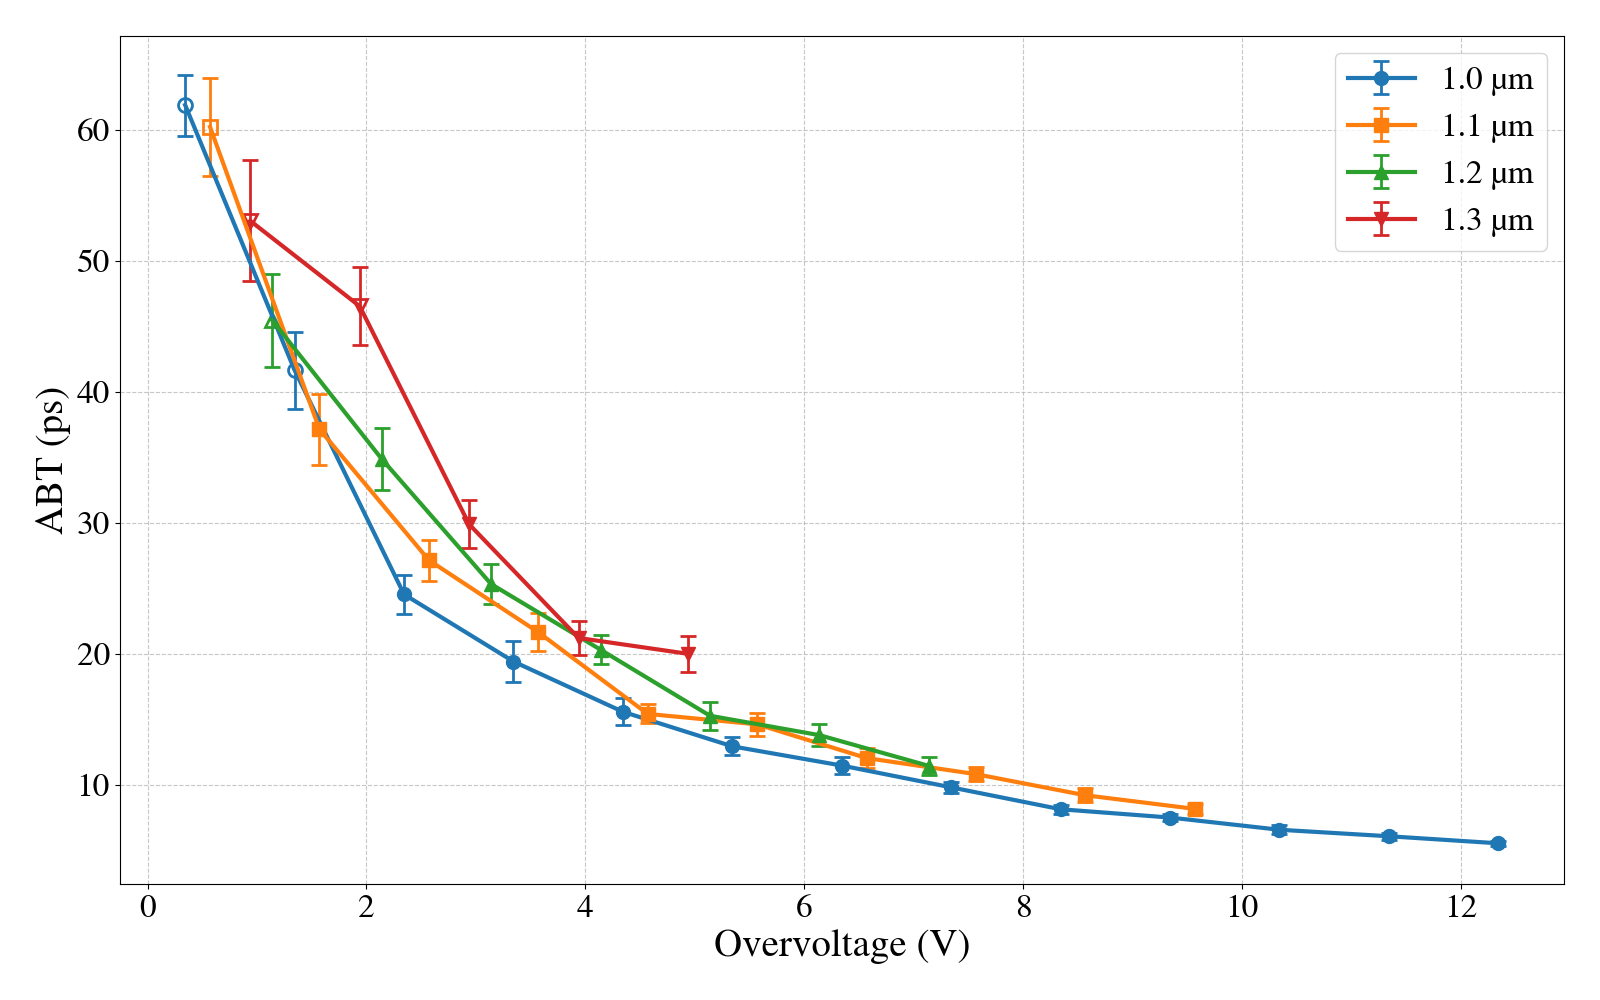

In [37]:
plt.close("all")
fig, ax = plt.subplots(figsize=(16, 10))
plot_vs_overvoltage(ax, "time", 1, hollow_long_abt=True)
ax.set_xlabel("Overvoltage (V)", fontsize=28)
ax.set_ylabel("ABT (ps)", fontsize=28)
ax.grid(True, linestyle="--", alpha=0.7)
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "avalanche_buildup/buildup_time")
plt.show()

## Relative current slope

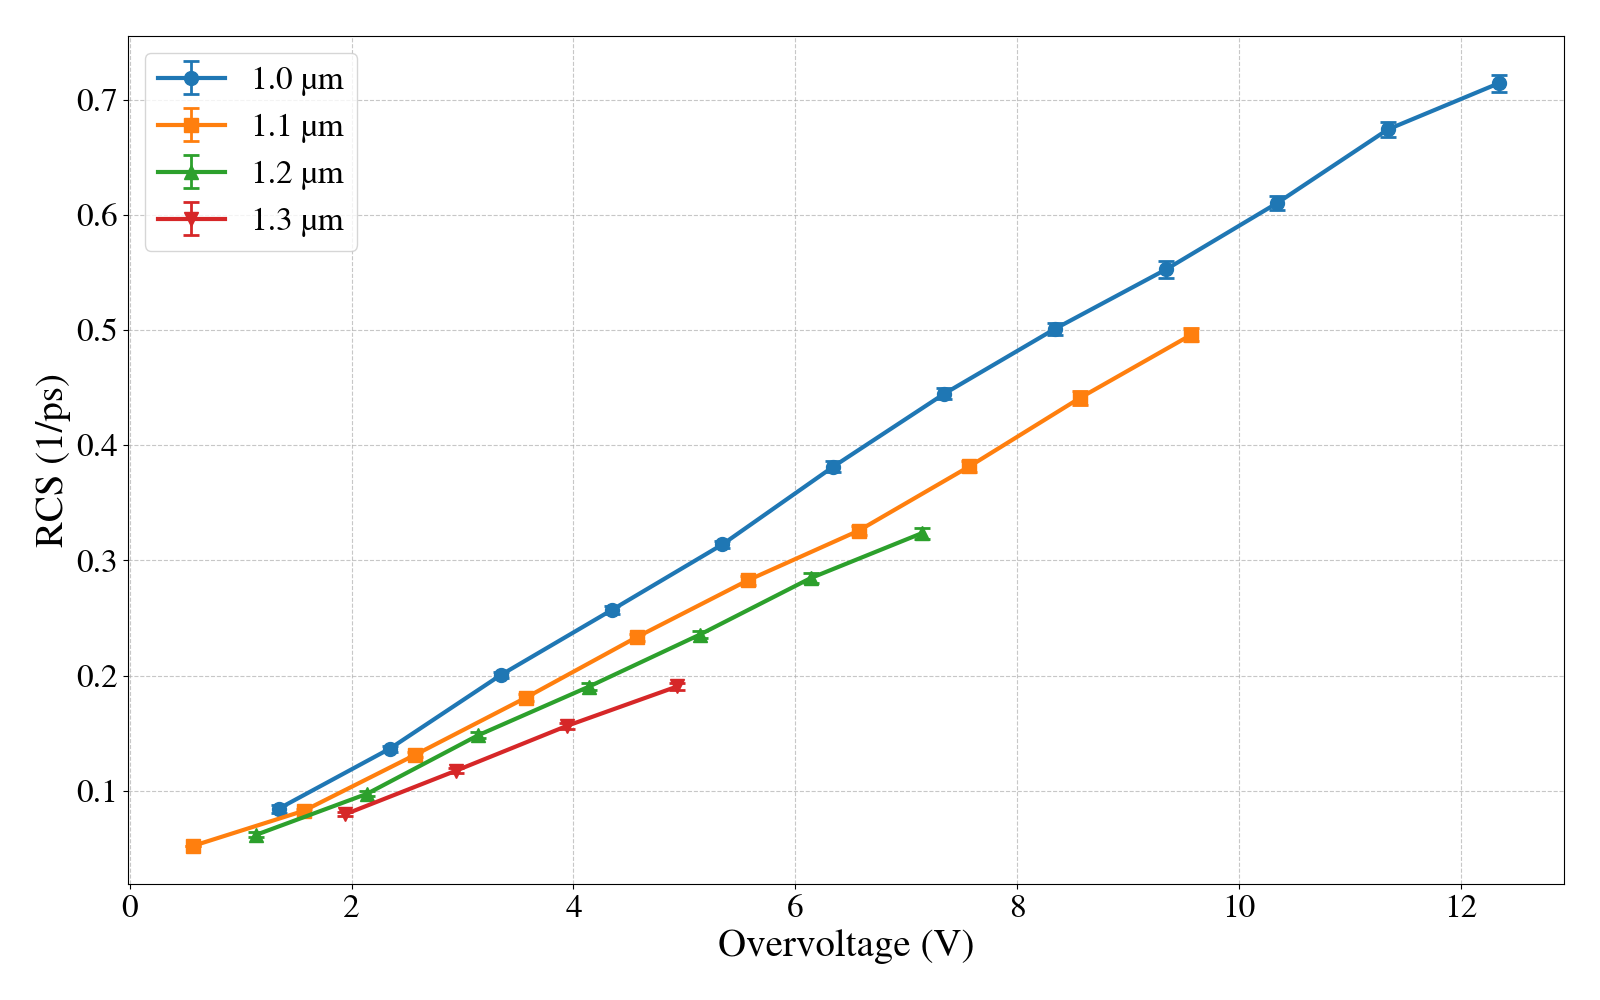

In [38]:
plt.close("all")
fig, ax = plt.subplots(figsize=(16, 10))
plot_vs_overvoltage(ax, "slope", 1e-12)
ax.set_xlabel("Overvoltage (V)", fontsize=28)
ax.set_ylabel("RCS (1/ps)", fontsize=28)
ax.grid(True, linestyle="--", alpha=0.7)
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "avalanche_buildup/relative_current_slope")
plt.show()

## ABT × RCS
Mean over the avalanching seeds of the product ABT × RCS of each seed, with error bars std/$\sqrt{n}$.

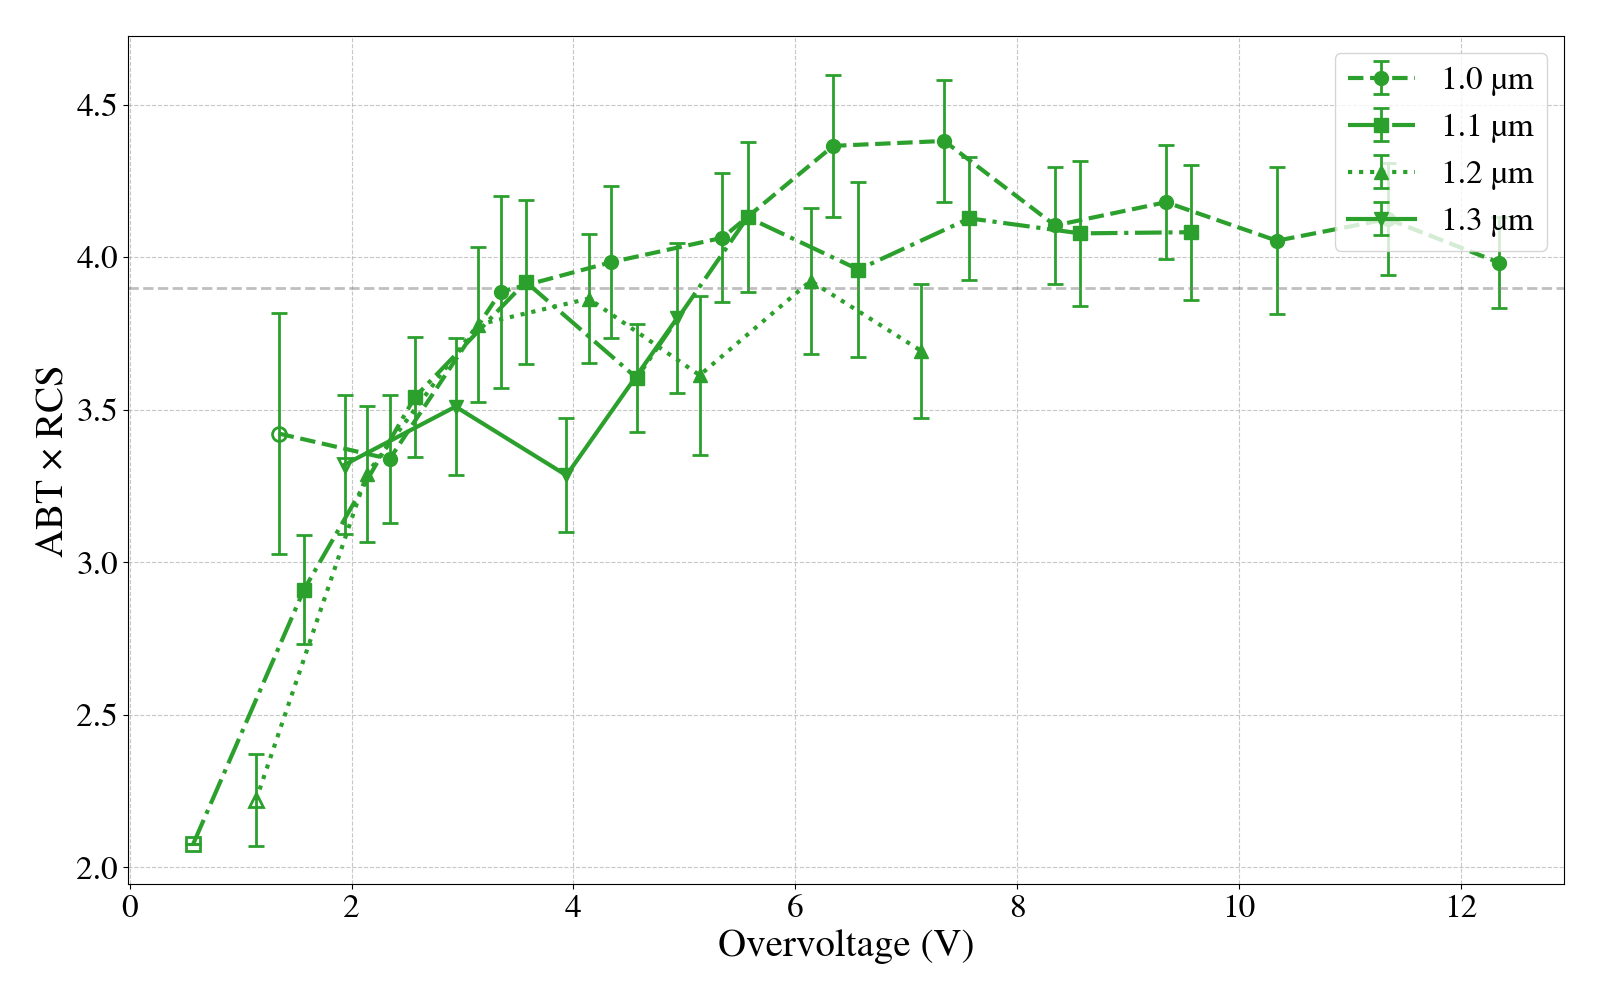

In [39]:
plt.close("all")
abt_x_rcs_ref = 3.9  # reference value, dashed grey line
fig, ax = plt.subplots(figsize=(16, 10))
plot_vs_overvoltage(ax, "product", 1, prefix_colors[2], hollow_long_abt=True)
ax.axhline(abt_x_rcs_ref, color="grey", linestyle="--", linewidth=2, alpha=0.5)
ax.set_xlabel("Overvoltage (V)", fontsize=28)
ax.set_ylabel("ABT × RCS", fontsize=28)
ax.grid(True, linestyle="--", alpha=0.7)
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "avalanche_buildup/abt_x_rcs")
plt.show()

## Fit summary
- Linear fit RCS = s·V_OV + c (points with V_OV ≥ `rcs_fit_min_vov`, unweighted); the line crosses zero at
  $|V| = |V_{BD}| - c/s$, compared with $V_{BD}$ from the probability fit.
- Mean and standard deviation of ABT×RCS over the points with V_OV ≥ `abt_x_rcs_min_vov`, per DI and overall.

In [40]:
rcs_fit_min_vov = 1.0  # V, points used for the RCS linear fit
abt_x_rcs_min_vov = 4.0  # V, points used for the ABT x RCS statistics

print(f"RCS = s * V_OV + c, points with V_OV >= {rcs_fit_min_vov:g} V")
for prefix, data in results_by_prefix.items():
    sel = (data["vov"] >= rcs_fit_min_vov) & np.isfinite(data["avg_slope"])
    if sel.sum() < 4:  # polyfit needs more than 3 points for the covariance
        print(f"{prefix}: only {sel.sum()} points, no fit")
        continue
    (s, c), cov = np.polyfit(data["vov"][sel], data["avg_slope"][sel] * 1e-12, 1, cov=True)  # RCS in 1/ps
    s_err, c_err = np.sqrt(np.diag(cov))
    # zero crossing |V| = |VBD| - c/s; it does not depend on VBD (V_OV is |V| shifted by |VBD|)
    v_cross = abs(data["v0"]) - c / s
    v_cross_err = np.sqrt(cov[1, 1] / s**2 + c**2 * cov[0, 0] / s**4 - 2 * c * cov[0, 1] / s**3)
    sign = np.sign(data["v0"])
    print(f"{prefix} ({sel.sum()} points): s = {s:.4f} ± {s_err:.4f} 1/(ps V), c = {c:.4f} ± {c_err:.4f} 1/ps")
    print(f"    RCS = 0 at V = {sign * v_cross:.2f} ± {v_cross_err:.2f} V; "
          f"VBD (probability fit) = {data['v0']:.2f} ± {data['sigma_v0']:.2f} V; "
          f"difference {sign * (v_cross - abs(data['v0'])):+.2f} V")

print(f"\nABT x RCS, points with V_OV >= {abt_x_rcs_min_vov:g} V (mean ± std over the points)")
pooled = []
for prefix, data in results_by_prefix.items():
    values = data["avg_product"][(data["vov"] >= abt_x_rcs_min_vov) & np.isfinite(data["avg_product"])]
    pooled.extend(values)
    if len(values):
        print(f"{prefix}: {np.mean(values):.3f} ± {np.std(values):.3f} ({len(values)} points)")
    else:
        print(f"{prefix}: no points")
if pooled:
    print(f"overall: {np.mean(pooled):.3f} ± {np.std(pooled):.3f} ({len(pooled)} points)")

RCS = s * V_OV + c, points with V_OV >= 1 V
1.0 µm (12 points): s = 0.0585 ± 0.0006 1/(ps V), c = 0.0053 ± 0.0043 1/ps
    RCS = 0 at V = -32.57 ± 0.07 V; VBD (probability fit) = -32.66 ± 0.17 V; difference +0.09 V
1.1 µm (9 points): s = 0.0513 ± 0.0007 1/(ps V), c = -0.0019 ± 0.0041 1/ps
    RCS = 0 at V = -35.47 ± 0.08 V; VBD (probability fit) = -35.43 ± 0.20 V; difference -0.04 V
1.2 µm (7 points): s = 0.0446 ± 0.0007 1/(ps V), c = 0.0072 ± 0.0031 1/ps
    RCS = 0 at V = -37.70 ± 0.07 V; VBD (probability fit) = -37.86 ± 0.12 V; difference +0.16 V
1.3 µm (4 points): s = 0.0373 ± 0.0007 1/(ps V), c = 0.0078 ± 0.0024 1/ps
    RCS = 0 at V = -39.85 ± 0.07 V; VBD (probability fit) = -40.06 ± 0.21 V; difference +0.21 V

ABT x RCS, points with V_OV >= 4 V (mean ± std over the points)
1.0 µm: 4.138 ± 0.139 (9 points)
1.1 µm: 3.997 ± 0.185 (6 points)
1.2 µm: 3.773 ± 0.125 (4 points)
1.3 µm: 3.802 ± 0.000 (1 points)
overall: 4.006 ± 0.207 (20 points)
